# Garbage Classification — Tiền xử lý (Preprocessing)

Notebook này nối tiếp `EDA.ipynb`. Thứ tự các bước:

1. Kiểm kê lại dữ liệu (đọc ảnh, tính hash) — để notebook này chạy độc lập, không phụ thuộc kernel của EDA.
2. Phát hiện các nhóm ảnh trùng **khác nhãn**, áp dụng luôn nhãn đúng (đã xác định bằng mắt từ trước, hardcode
   trong dict `LABEL_CORRECTIONS` — chỉ cần Run All, không cần thao tác file CSV thủ công).
3. Xóa bớt ảnh trùng **cùng nhãn** (chỉ giữ 1 ảnh đại diện/nhóm).
4. Chia train/val/test (stratified) — làm trên danh sách file đã làm sạch, **trước khi** đọc pixel. Kết quả
   lưu ra `data/train/train.csv`, `data/val/val.csv`, `data/test/test.csv`.
5. Tính class weight từ tập train (để xử lý lệch lớp).
6. Convert RGB + resize + normalize + augmentation — dùng chung các hàm trong file **`data_pipeline.py`**
   (đặt cùng thư mục với notebook này), để phần làm model của nhóm `import` lại được, không cần copy code.
7. Kiểm tra nhanh pipeline bằng cách xem thử 1 batch.

**Giả định:** dùng TensorFlow/Keras (`tf.data`). Nếu nhóm dùng PyTorch, các bước 1–4 vẫn dùng được y nguyên
(toàn bộ dùng pandas), chỉ cần viết lại `data_pipeline.py` theo `Dataset`/`DataLoader` của PyTorch.

**Lưu ý:** nếu sau này phát hiện thêm ảnh gán nhầm nhãn, chỉ cần thêm dòng vào dict `LABEL_CORRECTIONS` ở
Bước 2 rồi Run All lại — không cần file CSV riêng.

**Để phần làm model dùng lại:** import các hàm từ `data_pipeline.py` và đọc
3 file `data/train/train.csv` / `data/val/val.csv` / `data/test/test.csv` — cần giữ thư mục ảnh gốc `data/raw/garbage_classification` vì CSV chỉ chứa đường dẫn tương đối. Cả nhóm dùng cùng bộ CSV, không tự chia lại.

Trong notebook model, sửa đường dẫn repo rồi thiết lập import:
```python
from pathlib import Path
import sys
import tensorflow as tf
PROJECT_DIR = Path(r'C:/duong_dan/deep_learning-waste_classification')
sys.path.insert(0, str(PROJECT_DIR / 'preprocess'))
tf.keras.utils.set_random_seed(42)
```

**Simple CNN / Complex CNN:**
```python
from data_pipeline import CLASSES, make_custom_cnn_datasets
train_ds, val_ds, test_ds, class_weight_dict = make_custom_cnn_datasets(
    img_size=128, batch_size=32, seed=42, csv_dir=PROJECT_DIR / 'data',
)
```
Ảnh có shape `(batch, 128, 128, 3)`, pixel `[0,1]`. Không chia 255 hay thêm augmentation lần nữa.

**Transfer learning — ví dụ MobileNetV2:**
```python
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from data_pipeline import make_dataset, compute_class_weights, DATA_DIR
CSV_DIR = DATA_DIR.parent.parent
def build_split(name, training):
    return make_dataset(
        CSV_DIR / name / f'{name}.csv', training=training,
        img_size=224, batch_size=32, seed=42, normalize_fn=preprocess_input,
    )
train_ds = build_split('train', True)
val_ds = build_split('val', False)
test_ds = build_split('test', False)
class_weight_dict = compute_class_weights(CSV_DIR / 'train' / 'train.csv')
```
Model cần input `(224,224,3)` và không gọi preprocessing lần nữa. Khi đổi model pretrained, chọn kích thước và `preprocess_input` theo model đó; không cần chia lại CSV.

**Huấn luyện:** nhãn là số nguyên 0–11 theo `CLASSES`; dùng đầu ra 12 lớp với softmax và loss `sparse_categorical_crossentropy`. Truyền `class_weight=class_weight_dict` vào `model.fit(train_ds, validation_data=val_ds, ...)`. Chỉ dùng test sau khi chọn cấu hình/checkpoint bằng validation.


In [1]:
from pathlib import Path
import hashlib
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
import tensorflow as tf

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

CLASSES = [
    'battery', 'biological', 'brown-glass', 'cardboard', 'clothes',
    'green-glass', 'metal', 'paper', 'plastic', 'shoes',
    'trash', 'white-glass'
]

IMG_SIZE = 128       # kích thước ảnh đầu vào cho Simple/Complex CNN tự thiết kế
                     # -> nếu dùng transfer learning, đổi thành đúng size model pretrained yêu cầu (vd 224)
BATCH_SIZE = 32
VAL_RATIO = 0.15     # % dữ liệu dùng cho validation
TEST_RATIO = 0.15    # % dữ liệu dùng cho test

# Tìm dữ liệu cả khi chạy từ thư mục dự án hoặc thư mục preprocess (giống notebook EDA)
candidates = [
    base / relative
    for base in (Path.cwd(), *Path.cwd().parents)
    for relative in [
        'data/raw/garbage_classification',
        'deep_learning-waste_classification/data/raw/garbage_classification'
    ]
]
DATA_DIR = next((p.resolve() for p in candidates if p.is_dir()), None)
assert DATA_DIR is not None, 'Không tìm thấy thư mục dữ liệu. Hãy kiểm tra lại đường dẫn.'

CSV_DIR = DATA_DIR.parent.parent  # project/data
PIPELINE_DIR = CSV_DIR.parent / 'preprocess'
if str(PIPELINE_DIR) not in sys.path:
    sys.path.insert(0, str(PIPELINE_DIR))

assert 0 < VAL_RATIO < 1 and 0 < TEST_RATIO < 1 and VAL_RATIO + TEST_RATIO < 1
assert {p.name for p in DATA_DIR.iterdir() if p.is_dir()} == set(CLASSES)
PROCESSED_DIR = CSV_DIR / 'processed'
for folder in [PROCESSED_DIR, *(CSV_DIR / name for name in ('train', 'val', 'test'))]:
    folder.mkdir(parents=True, exist_ok=True)

print('Thư mục dữ liệu:', DATA_DIR)
print('Thư mục CSV:', CSV_DIR.resolve())


Thư mục dữ liệu: C:\Users\Lenovo\Documents\Deep Learning\Mid-term Project\deep_learning-waste_classification\data\raw\garbage_classification
Thư mục CSV: C:\Users\Lenovo\Documents\Deep Learning\Mid-term Project\deep_learning-waste_classification\data


## Bước 1. Kiểm kê lại dữ liệu

Đọc lại toàn bộ ảnh và tính SHA-256 cho từng ảnh (giống notebook EDA). EDA đã xác nhận **0 ảnh lỗi**,
nên ở đây không cần try/except phức tạp — vẫn giữ để an toàn nếu dataset có thay đổi.


In [2]:
EXTENSIONS = {'.jpg', '.jpeg', '.png'}

def file_hash(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

records = []
for class_dir in sorted(DATA_DIR.iterdir()):
    if not class_dir.is_dir():
        continue
    label = class_dir.name
    for img_path in sorted(class_dir.iterdir()):
        if img_path.suffix.lower() not in EXTENSIONS:
            continue
        try:
            with Image.open(img_path) as im:
                im.verify()
            with Image.open(img_path) as im:
                im.load()
            records.append({
                'filepath': img_path.relative_to(DATA_DIR).as_posix(),  # dùng / thống nhất trên mọi hệ điều hành
                'label': label,
                'file_hash': file_hash(img_path),
            })
        except Exception as exc:
            print(f'Bỏ qua ảnh lỗi: {img_path} ({exc})')

assert records, 'Không có ảnh hợp lệ.'
df = pd.DataFrame(records)
print(f'Tổng số ảnh hợp lệ: {len(df):,}')
display(df.head())


Tổng số ảnh hợp lệ: 15,515


,filepath,label,file_hash
0,battery/battery1.jpg,battery,65d0311205cb0148871bc14dec13314c0209ecd74095f9...
1,battery/battery10.jpg,battery,334466b4324a8c80f3204ef4c63cf6892ec20a954880af...
2,battery/battery100.jpg,battery,32efd926e244739e97b3ced8bd3b9e2ce01ca101972eb5...
3,battery/battery101.jpg,battery,49a84a86143beab927b8074c2d05855e4221c4e99137d5...
4,battery/battery102.jpg,battery,7e191fef8b4cd286fb635cf99ede490dc598c42c39df9c...


## Bước 2. Phát hiện & sửa ảnh trùng khác nhãn

Gom các ảnh có cùng `file_hash`. Với các nhóm có **nhiều hơn 1 nhãn** (khả năng gán nhầm nhãn ở dataset gốc),
in ra để đối chiếu, sau đó áp dụng luôn các nhãn đúng đã xác định từ trước (xem bằng mắt ở bước EDA):

| File | Nhãn cũ | Nhãn đúng |
|---|---|---|
| `metal/metal459.jpg` | metal | white-glass |
| `plastic/plastic159.jpg` | plastic | white-glass |
| `white-glass/white-glass761.jpg` | white-glass | plastic |

Nếu sau này phát hiện thêm ảnh gán nhầm nhãn (không nhất thiết phải là ảnh trùng lặp), chỉ cần thêm dòng vào
dict `LABEL_CORRECTIONS` bên dưới rồi chạy lại — không cần thao tác file CSV thủ công nữa.


In [3]:
dup_counts = df['file_hash'].value_counts()
dup_hashes = dup_counts[dup_counts > 1].index

groups = []
for i, h in enumerate(dup_hashes, start=1):
    members = df.loc[df.file_hash == h]
    groups.append({
        'group_id': f'group_{i:03d}',
        'file_hash': h,
        'n_images': len(members),
        'cross_label': members.label.nunique() > 1,
        'files': members['filepath'].tolist(),
        'labels': members['label'].tolist(),
    })

cross_label_groups = [g for g in groups if g['cross_label']]
same_label_groups = [g for g in groups if not g['cross_label']]

print(f'Tổng số nhóm trùng: {len(groups)}')
print(f'  - Khác nhãn: {len(cross_label_groups)}')
print(f'  - Cùng nhãn: {len(same_label_groups)}')

if cross_label_groups:
    print('Chi tiết các nhóm khác nhãn (đối chiếu với LABEL_CORRECTIONS bên dưới):')
    for g in cross_label_groups:
        print(f"  {g['group_id']}: {list(zip(g['files'], g['labels']))}")

# Nhãn đúng đã xác định bằng mắt (xem hướng dẫn ở ô markdown phía trên).
# Thêm/sửa dòng ở đây nếu phát hiện thêm ảnh gán nhầm nhãn.
LABEL_CORRECTIONS = {
    'metal/metal459.jpg': 'white-glass',
    'plastic/plastic159.jpg': 'white-glass',
    'white-glass/white-glass761.jpg': 'plastic',
}

applied = []
for filepath, correct_label in LABEL_CORRECTIONS.items():
    mask = df['filepath'] == filepath
    if not mask.any():
        print(f'Cảnh báo: không tìm thấy {filepath} trong dữ liệu hiện tại, bỏ qua.')
        continue
    if correct_label not in CLASSES:
        print(f"Cảnh báo: '{correct_label}' không nằm trong CLASSES, bỏ qua {filepath}.")
        continue
    old_label = df.loc[mask, 'label'].iloc[0]
    df.loc[mask, 'label'] = correct_label
    applied.append({'filepath': filepath, 'old_label': old_label, 'new_label': correct_label})

applied_df = pd.DataFrame(applied, columns=['filepath', 'old_label', 'new_label'])
applied_df.to_csv(PROCESSED_DIR / 'label_corrections_applied.csv', index=False, encoding='utf-8-sig')
print(f'Đã áp dụng {len(applied_df)} lượt sửa nhãn. Chi tiết lưu ở data/processed/label_corrections_applied.csv')
display(applied_df)


Tổng số nhóm trùng: 18
  - Khác nhãn: 3
  - Cùng nhãn: 15
Chi tiết các nhóm khác nhãn (đối chiếu với LABEL_CORRECTIONS bên dưới):
  group_016: [('metal/metal459.jpg', 'metal'), ('white-glass/white-glass412.jpg', 'white-glass')]
  group_017: [('plastic/plastic159.jpg', 'plastic'), ('white-glass/white-glass129.jpg', 'white-glass')]
  group_018: [('plastic/plastic556.jpg', 'plastic'), ('white-glass/white-glass761.jpg', 'white-glass')]
Đã áp dụng 3 lượt sửa nhãn. Chi tiết lưu ở data/processed/label_corrections_applied.csv


,filepath,old_label,new_label
0,metal/metal459.jpg,metal,white-glass
1,plastic/plastic159.jpg,plastic,white-glass
2,white-glass/white-glass761.jpg,white-glass,plastic


## Bước 3. Xóa bớt ảnh trùng cùng nhãn

Với các nhóm ảnh trùng hoàn toàn và **cùng nhãn** (sau khi đã áp dụng sửa nhãn ở Bước 2), chỉ giữ lại
1 ảnh đại diện mỗi nhóm (chọn ảnh có tên file nhỏ nhất để kết quả ổn định mỗi lần chạy lại), xóa các ảnh còn lại
khỏi danh sách xử lý. **Không xóa file gốc trên ổ đĩa** — chỉ loại khỏi dataframe dùng để train, an toàn hơn nếu
cần xem lại sau này.


In [4]:
# Tính lại nhóm trùng dựa trên nhãn đã được cập nhật ở Bước 2
dup_counts = df['file_hash'].value_counts()
dup_hashes = dup_counts[dup_counts > 1].index

rows_to_drop = []
removed_log = []
for h in dup_hashes:
    members = df.loc[df.file_hash == h].sort_values('filepath')
    if members['label'].nunique() > 1:
        # Vẫn còn khác nhãn (chưa được sửa ở Bước 2) -> không tự xử lý, in cảnh báo để bạn biết
        print(f'Cảnh báo: nhóm hash {h[:8]}... vẫn còn khác nhãn, chưa xử lý ở Bước 3:')
        display(members[['filepath', 'label']])
        continue
    keep, *drop = members.index.tolist()  # giữ ảnh đầu tiên (đã sort theo filepath), xóa phần còn lại
    rows_to_drop.extend(drop)
    for idx in drop:
        removed_log.append({
            'removed_filepath': df.loc[idx, 'filepath'],
            'kept_filepath': df.loc[keep, 'filepath'],
            'label': df.loc[idx, 'label'],
        })

removed_df = pd.DataFrame(removed_log, columns=['removed_filepath', 'kept_filepath', 'label'])
removed_df.to_csv(PROCESSED_DIR / 'removed_duplicates.csv', index=False, encoding='utf-8-sig')

before = len(df)
df = df.drop(index=rows_to_drop).reset_index(drop=True)

assert df['file_hash'].is_unique, (
    "Còn ảnh trùng chưa xử lý. "
    "Hãy kiểm tra các nhóm khác nhãn ở Bước 2 trước khi chia tập."
)
after = len(df)

print(f'Số ảnh trước khi xóa trùng: {before:,}')
print(f'Số ảnh đã xóa (trùng cùng nhãn): {before - after}')
print(f'Số ảnh còn lại: {after:,}')
print(f'Chi tiết ảnh đã xóa: data/processed/removed_duplicates.csv')


Số ảnh trước khi xóa trùng: 15,515
Số ảnh đã xóa (trùng cùng nhãn): 19
Số ảnh còn lại: 15,496
Chi tiết ảnh đã xóa: data/processed/removed_duplicates.csv


## Bước 4. Phân bố lớp sau khi làm sạch

Xem lại phân bố lớp sau dedup + sửa nhãn, để biết mức độ lệch lớp thực tế sẽ dùng khi tính class weight.


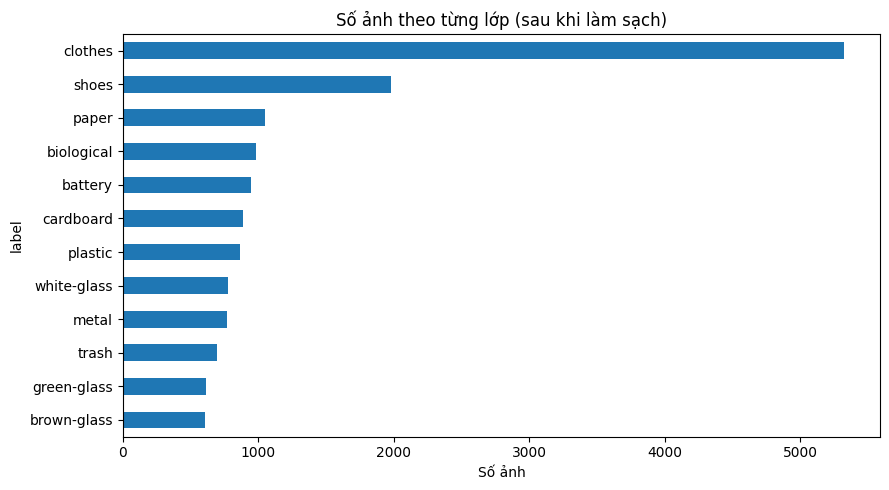

Tổng số ảnh: 15,496
Lệch lớp (max/min): 8.77 lần


In [5]:
counts = df['label'].value_counts().reindex(CLASSES, fill_value=0)

fig, ax = plt.subplots(figsize=(9, 5))
counts.sort_values().plot(kind='barh', ax=ax)
ax.set_xlabel('Số ảnh')
ax.set_title('Số ảnh theo từng lớp (sau khi làm sạch)')
plt.tight_layout()
plt.show()

print(f'Tổng số ảnh: {len(df):,}')
print(f'Lệch lớp (max/min): {counts.max() / counts.min():.2f} lần')


## Bước 5. Chia train/val/test (stratified)

Chia trên **danh sách file đã làm sạch**, chưa đọc pixel ảnh — chỉ cần cột `filepath` và `label`.
Dùng `stratify=label` để giữ đúng tỉ lệ 12 lớp ở cả 3 tập.

Lưu ý: hiện chỉ loại ảnh trùng byte (SHA-256 file). Các cặp gần trùng pHash chưa được xử lý; cần kiểm tra nguy cơ ảnh gần trùng nằm ở các tập khác nhau trước khi đánh giá mô hình.


In [6]:
train_df, temp_df = train_test_split(
    df, test_size=VAL_RATIO + TEST_RATIO, stratify=df['label'], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=TEST_RATIO / (VAL_RATIO + TEST_RATIO), stratify=temp_df['label'], random_state=SEED
)

# Kiểm tra không trùng đường dẫn/hash giữa các tập và không mất bản ghi.
splits = [train_df, val_df, test_df]
assert sum(len(part) for part in splits) == len(df)
for column in ('filepath', 'file_hash'):
    for a in range(len(splits)):
        for b in range(a + 1, len(splits)):
            assert set(splits[a][column]).isdisjoint(splits[b][column]), column

for name, split_df in [('train', train_df), ('val', val_df), ('test', test_df)]:
    split_df.to_csv(CSV_DIR / name / f'{name}.csv', index=False, encoding='utf-8-sig')

print(f'Train: {len(train_df):,} | Val: {len(val_df):,} | Test: {len(test_df):,}')
display(pd.DataFrame({
    'train': train_df.label.value_counts().reindex(CLASSES, fill_value=0),
    'val': val_df.label.value_counts().reindex(CLASSES, fill_value=0),
    'test': test_df.label.value_counts().reindex(CLASSES, fill_value=0),
}))


Train: 10,847 | Val: 2,324 | Test: 2,325


,train,val,test
label,,,
battery,661,142,142
biological,689,148,148
brown-glass,425,91,91
cardboard,624,133,134
clothes,3727,798,799
green-glass,430,92,92
metal,537,116,115
paper,735,157,158
plastic,605,130,129


## Bước 6. Class weight từ tập train

Dùng hàm `compute_class_weights()` trong `data_pipeline.py` (đã tách riêng để phần model dùng lại được),
tính trên **phân bố nhãn của tập train** — vì đây là trọng số dùng khi tính loss lúc huấn luyện, chỉ nên
phản ánh đúng dữ liệu mô hình thực sự "nhìn thấy" khi train.


In [7]:
from data_pipeline import compute_class_weights, CLASSES

class_weight_dict = compute_class_weights(CSV_DIR / 'train' / 'train.csv')

print('Class weight (dùng khi model.fit(..., class_weight=class_weight_dict)):')
for c, i in zip(CLASSES, range(len(CLASSES))):
    print(f'  {c:<14} -> {class_weight_dict[i]:.3f}')


Class weight (dùng khi model.fit(..., class_weight=class_weight_dict)):
  battery        -> 1.367
  biological     -> 1.312
  brown-glass    -> 2.127
  cardboard      -> 1.449
  clothes        -> 0.243
  green-glass    -> 2.102
  metal          -> 1.683
  paper          -> 1.230
  plastic        -> 1.494
  shoes          -> 0.653
  trash          -> 1.852
  white-glass    -> 1.668


## Bước 7. Convert RGB + resize + normalize — dùng chung file `data_pipeline.py`

Toàn bộ logic convert RGB, resize và tạo `tf.data.Dataset` đã được tách ra file riêng **`data_pipeline.py`**
(cùng thư mục với notebook này). Vì đây là notebook tiền xử lý dùng chung, mình gọi đúng hàm dành cho
**Simple CNN / Complex CNN** (`make_custom_cnn_datasets`) để demo và kiểm tra pipeline — 2 bạn làm CNN tự
thiết kế sau này cũng gọi y hệt hàm này trong notebook model của họ. Bạn làm Transfer learning tự import
`preprocess_input` của model pretrained rồi gọi `make_dataset()` với đủ tham số và `normalize_fn=preprocess_input`,
như ví dụ ở đầu notebook. Pipeline không nhận tham số `backbone`; người train tự khởi tạo model pretrained.


In [8]:
from data_pipeline import make_custom_cnn_datasets

# class_weight_dict đã được tính và in ra ở Bước 6 rồi -> bỏ qua giá trị này (dùng "_"),
# Hàm vẫn tính lại class weight; dấu _ chỉ bỏ qua kết quả trả về để giữ biến đã có.
train_ds, val_ds, test_ds, _ = make_custom_cnn_datasets(
    img_size=IMG_SIZE, batch_size=BATCH_SIZE, seed=SEED, csv_dir=CSV_DIR,
)

print('Đã tạo train_ds, val_ds, test_ds (có augmentation ở train_ds, không có ở val_ds/test_ds).')


Đã tạo train_ds, val_ds, test_ds (có augmentation ở train_ds, không có ở val_ds/test_ds).


## Bước 8. Augmentation — chỉ áp dụng cho tập train

Augmentation (lật ngang, xoay nhẹ, đổi nhẹ độ sáng/tương phản) đã được gắn **sẵn bên trong**
`make_dataset(..., training=True)` trong `data_pipeline.py` — khi `training=True`, hàm tự động thêm bước
augmentation; khi `training=False` (val/test) thì không. Vì vậy `train_ds` ở Bước 7 đã có augmentation rồi,
không cần thêm thao tác gì ở đây nữa.

**Lý do augmentation nhẹ:** rác thải trong thực tế xuất hiện ở nhiều góc/ánh sáng khác nhau nên lật/xoay nhẹ
là hợp lý; tránh biến đổi màu quá mạnh vì một số lớp phân biệt nhau chủ yếu qua màu (`green-glass` /
`brown-glass` / `white-glass`).

**Vì sao chỉ áp dụng cho train:** val/test phải phản ánh đúng dữ liệu thật để đánh giá khách quan.


In [9]:
# Không cần code thêm ở đây — augmentation đã nằm trong data_pipeline.make_dataset() ở Bước 7.
# Ô này chỉ để xác nhận lại: train_ds có augmentation, val_ds/test_ds thì không (xem Bước 9 để kiểm tra bằng mắt).
print('train_ds: có augmentation (training=True)')
print('val_ds:   không augmentation (training=False)')
print('test_ds:  không augmentation (training=False)')


train_ds: có augmentation (training=True)
val_ds:   không augmentation (training=False)
test_ds:  không augmentation (training=False)


## Bước 9. Kiểm tra nhanh pipeline

Lấy thử 1 batch từ `train_ds` (có augmentation) và `val_ds` (không augmentation) để chắc chắn pipeline chạy đúng
trước khi đưa vào model.


train_ds (có augmentation): batch shape = (32, 128, 128, 3), dtype = <dtype: 'float32'>, giá trị pixel trong [0.000, 1.000]


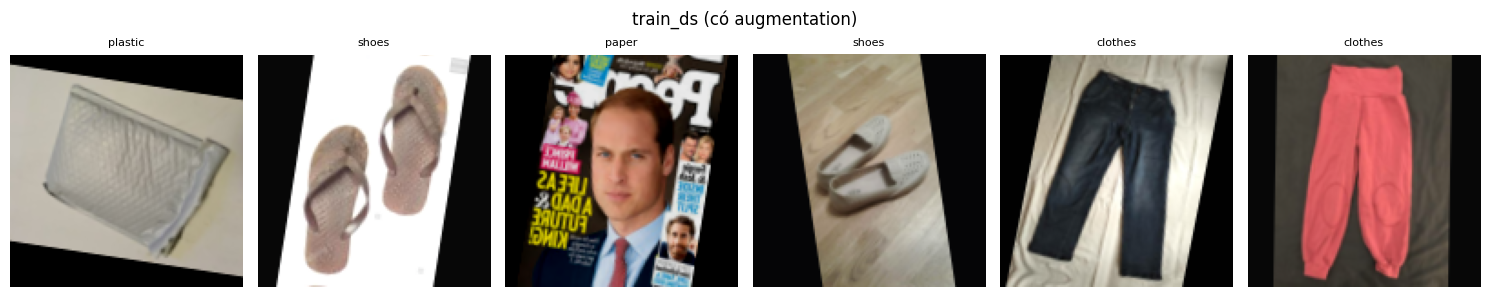

val_ds (không augmentation): batch shape = (32, 128, 128, 3), dtype = <dtype: 'float32'>, giá trị pixel trong [0.000, 1.000]


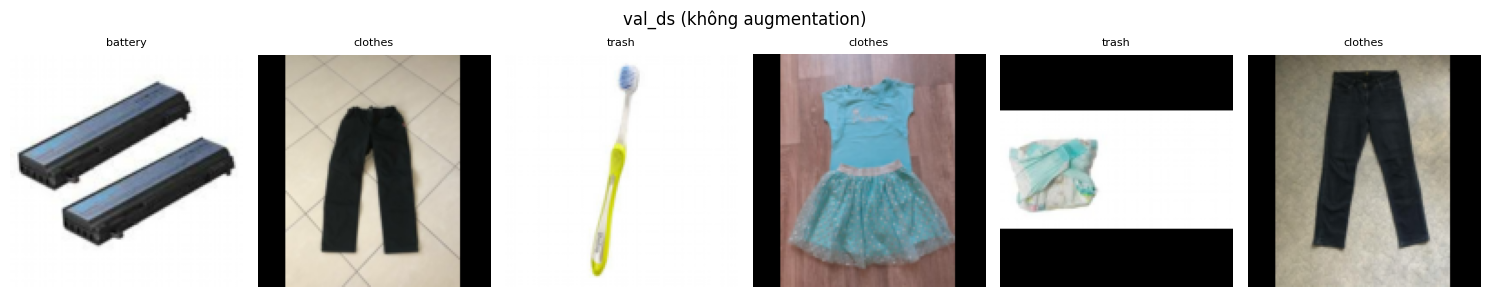

test_ds (không augmentation): batch shape = (32, 128, 128, 3), dtype = <dtype: 'float32'>, giá trị pixel trong [0.000, 1.000]


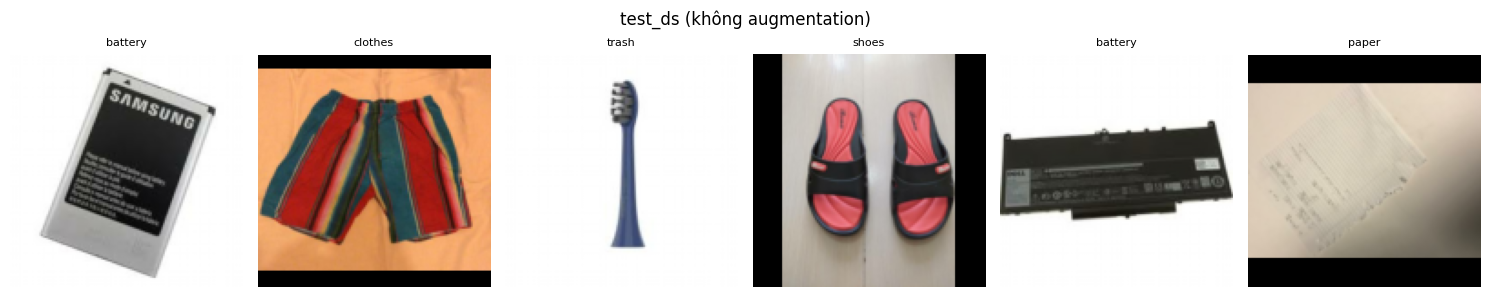

In [10]:
for name, ds in [('train_ds (có augmentation)', train_ds), ('val_ds (không augmentation)', val_ds), ('test_ds (không augmentation)', test_ds)]:
    images, labels = next(iter(ds))
    assert tuple(images.shape[1:]) == (IMG_SIZE, IMG_SIZE, 3)
    assert images.dtype == tf.float32
    tf.debugging.assert_all_finite(images, 'Ảnh chứa NaN/Inf')
    tf.debugging.assert_greater_equal(images, 0.0)
    tf.debugging.assert_less_equal(images, 1.0)
    tf.debugging.assert_greater_equal(labels, tf.zeros_like(labels))
    tf.debugging.assert_less(labels, tf.cast(len(CLASSES), labels.dtype))
    print(f'{name}: batch shape = {images.shape}, dtype = {images.dtype}, '
          f'giá trị pixel trong [{images.numpy().min():.3f}, {images.numpy().max():.3f}]')

    fig, axes = plt.subplots(1, 6, figsize=(15, 3))
    for ax, img, lb in zip(axes, images[:6], labels[:6]):
        ax.imshow(img.numpy())
        ax.set_title(CLASSES[lb.numpy()], fontsize=8)
        ax.axis('off')
    fig.suptitle(name)
    plt.tight_layout()
    plt.show()


## Tổng kết bước tiền xử lý

In [11]:
print('=== TỔNG KẾT TIỀN XỬ LÝ ===')
print(f'- Ảnh sau khi làm sạch (dedup + sửa nhãn): {len(df):,}')
print(f'- Train / Val / Test: {len(train_df):,} / {len(val_df):,} / {len(test_df):,}')
print(f'- Kích thước ảnh đầu vào: {IMG_SIZE}x{IMG_SIZE}, batch size: {BATCH_SIZE}')
print(f'- Class weight (balanced) đã tính từ tập train, dùng khi model.fit(..., class_weight=class_weight_dict)')
print(f'- Augmentation: chỉ áp dụng cho train_ds (flip, rotation nhẹ, brightness/contrast nhẹ)')
print(f'- File CSV: data/processed/label_corrections_applied.csv, data/processed/removed_duplicates.csv, '
      f'data/train/train.csv, data/val/val.csv, data/test/test.csv')


=== TỔNG KẾT TIỀN XỬ LÝ ===
- Ảnh sau khi làm sạch (dedup + sửa nhãn): 15,496
- Train / Val / Test: 10,847 / 2,324 / 2,325
- Kích thước ảnh đầu vào: 128x128, batch size: 32
- Class weight (balanced) đã tính từ tập train, dùng khi model.fit(..., class_weight=class_weight_dict)
- Augmentation: chỉ áp dụng cho train_ds (flip, rotation nhẹ, brightness/contrast nhẹ)
- File CSV: data/processed/label_corrections_applied.csv, data/processed/removed_duplicates.csv, data/train/train.csv, data/val/val.csv, data/test/test.csv
